# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [51]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt


### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
import random

SEED = 42

def set_seed():
    random.seed(SEED)

numbers = list(range(10))
print("ДО set_seed():")
print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)
print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)
set_seed()
print("\nSeed зафіксовано:", SEED)


print("\nПІСЛЯ set_seed() з повторним set_seed():")
set_seed()
print("randint:", random.randint(1, 100))
set_seed()
print("randint:", random.randint(1, 100))
set_seed()
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)
set_seed()
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)


print("\nПІСЛЯ set_seed() без проміжного set_seed():")
set_seed()
print("randint:", random.randint(1, 100))
print("randint:", random.randint(1, 100))
numbers = list(range(10))
random.shuffle(numbers)
print("shuffle:", numbers)
random.shuffle(numbers)
print("shuffle:", numbers)

ДО set_seed():
randint: 84
shuffle: [4, 9, 2, 1, 5, 6, 7, 0, 3, 8]
randint: 63
shuffle: [0, 4, 1, 6, 8, 5, 3, 9, 2, 7]

Seed зафіксовано: 42

ПІСЛЯ set_seed() з повторним set_seed():
randint: 82
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

ПІСЛЯ set_seed() без проміжного set_seed():
randint: 82
randint: 15
shuffle: [7, 5, 2, 8, 9, 6, 1, 3, 4, 0]
shuffle: [6, 8, 2, 4, 9, 1, 3, 5, 0, 7]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [34]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
eye_arr = np.eye(4)
random_arr = np.random.randint(0, 10, size=(3, 3))

print(eye_arr)
print(random_arr)

print(eye_arr.ndim)
print(random_arr.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 4 2]
 [3 9 9]
 [0 7 5]]
2
2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
grades = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])
mean = np.mean(grades)
std = np.std(grades)
z_grades = (grades - mean) / std
print("Середнє:", mean)
print("Стандартне відхилення:", std)
print("Z-normalized:", z_grades)

Середнє: 81.1
Стандартне відхилення: 10.76522178127325
Z-normalized: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [35]:
df = pd.DataFrame({
    "name": ["Ярослав", "Саша", "Вадім", "Богдан", "Паша"],
    "score": [95, 94, 93, 81, 70]
})

top = df[df["score"] > 80].sort_values("score", ascending=False)

print(top)

      name  score
0  Ярослав     95
1     Саша     94
2    Вадім     93
3   Богдан     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [36]:

df["grade"] = df["score"].apply(
    lambda score: "A" if score >= 90 else "B" if score >= 75 else "C"
)

print(df)

      name  score grade
0  Ярослав     95     A
1     Саша     94     A
2    Вадім     93     A
3   Богдан     81     B
4     Паша     70     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [37]:
zeros_tensor = torch.zeros(2, 3)

full_tensor = torch.full((2, 3), 7)

print("zeros_tensor:")
print("shape:", zeros_tensor.shape)
print("dtype:", zeros_tensor.dtype)

print("\nfull_tensor:")
print("shape:", full_tensor.shape)
print("dtype:", full_tensor.dtype)

zeros_tensor:
shape: torch.Size([2, 3])
dtype: torch.float32

full_tensor:
shape: torch.Size([2, 3])
dtype: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [38]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [39]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)

tensor([[1, 2],
        [3, 4]])
tensor([[0.6070, 0.1580, 0.3182],
        [0.8730, 0.6479, 0.5148],
        [0.2606, 0.9601, 0.4955]])


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [40]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2

y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт:", 2 * n)
print("Результати збігаються:", x.grad.item() == 2 * n)

Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0
Результати збігаються: True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [42]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

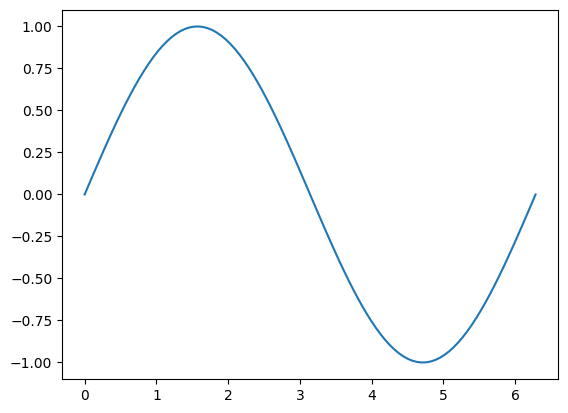

In [43]:
xs = np.linspace(0, 2 * np.pi, 100)

plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

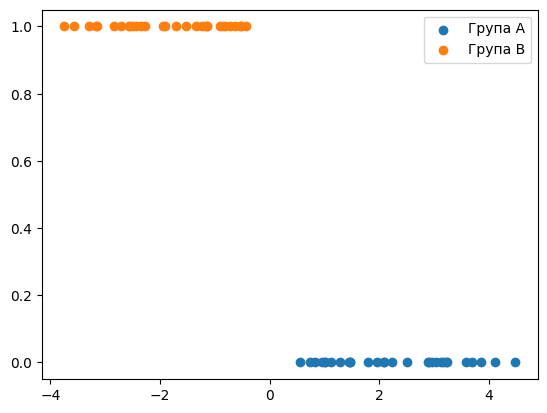

In [48]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(group_a, np.zeros(30), color="C0", label="Група A")
plt.scatter(group_b, np.ones(30), color="C1", label="Група B")

plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

w = 2.4941
b = 1.0598
loss = 0.9629


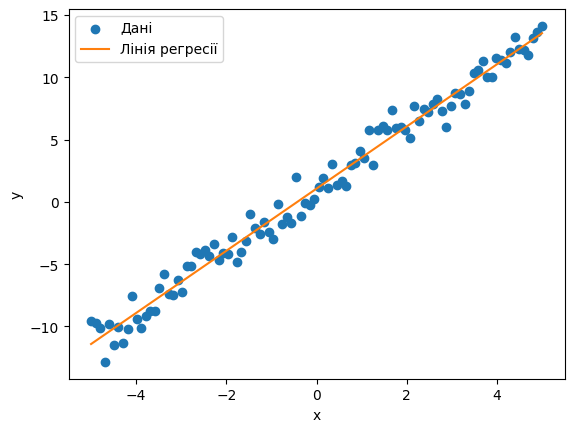

In [47]:
torch.manual_seed(42)

x = torch.linspace(-5, 5, 100)
w_true = 2.5
b_true = 1.0

epsilon = torch.randn(100)
y = w_true * x + b_true + epsilon

w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

lr = 0.01
epochs = 1000

for epoch in range(epochs):
    y_pred = w * x + b

    loss = ((y_pred - y) ** 2).mean()

    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    w.grad.zero_()
    b.grad.zero_()

print(f"w = {w.item():.4f}")
print(f"b = {b.item():.4f}")
print(f"loss = {loss.item():.4f}")

plt.scatter(x.numpy(), y.numpy(), label="Дані")
plt.plot(x.numpy(), (w * x + b).detach().numpy(),
         color="C1", label="Лінія регресії")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

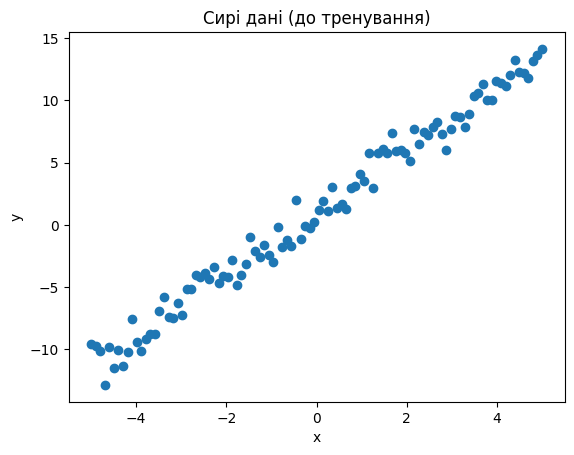

In [66]:
plt.scatter(x.numpy(), y.numpy())

plt.xlabel("x")
plt.ylabel("y")

plt.title("Сирі дані (до тренування)")

plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [70]:
perm = torch.randperm(len(x))

x_shuffled = x[perm]
y_shuffled = y[perm]

n_train = int(0.70 * len(x_shuffled))
n_val = int(0.15 * len(x_shuffled))

x_train1 = x_shuffled[:n_train]
y_train1 = y_shuffled[:n_train]

x_val1 = x_shuffled[n_train:n_train + n_val]
y_val1 = y_shuffled[n_train:n_train + n_val]

x_test1 = x_shuffled[n_train + n_val:]
y_test1 = y_shuffled[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 70/15/15


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [98]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)
snapshots = []

x_train1 = x_train1.unsqueeze(1)
y_train1 = y_train1.unsqueeze(1)


In [102]:
for epoch in range(100):
    optimizer.zero_grad()
    y_pred = task1_model(x_train1)
    loss = loss_fn(y_pred, y_train1)
    loss.backward()
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)

        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))

        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {w_true:.1f})  "
              f"b={task1_model.bias.item():.4f} (true {b_true:.1f})")


epoch    0  loss=0.934231  w=2.5130 (true 2.5)  b=1.0759 (true 1.0)
epoch   30  loss=0.934231  w=2.5130 (true 2.5)  b=1.0759 (true 1.0)
epoch   60  loss=0.934231  w=2.5130 (true 2.5)  b=1.0759 (true 1.0)
epoch   90  loss=0.934231  w=2.5130 (true 2.5)  b=1.0759 (true 1.0)
epoch   99  loss=0.934231  w=2.5130 (true 2.5)  b=1.0759 (true 1.0)


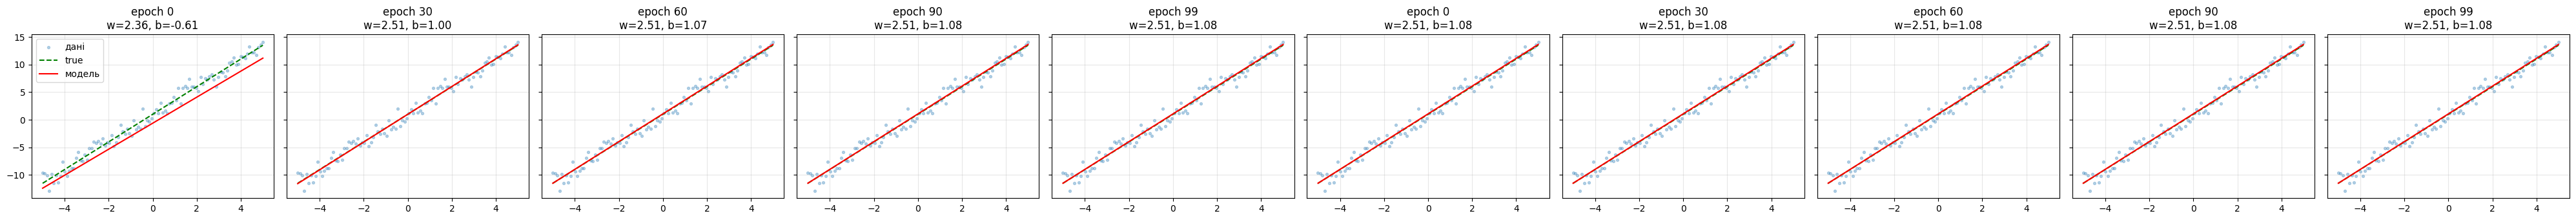

In [96]:
with torch.no_grad():
    y_line_true = w_true * x_line + b_true

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)

for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x.numpy(), y.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [105]:
MODEL_PATH = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(task1_model.state_dict(), MODEL_PATH)



**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Власний сценарій: кількість годин навчання на тиждень → результат тесту. Залежність задається формулою y = 5x + 40 + ε, де ε — випадковий шум.


In [108]:
torch.manual_seed(42)

x2 = torch.linspace(0, 10, 100)
y2 = 5 * x2 + 40 + torch.randn(100) * 5

df = pd.DataFrame({
    "hours": x2.numpy(),
    "score": y2.numpy()
})

DATASET_PATH = os.path.join(ARTIFACT_DIR, "dataset.csv")
df.to_csv(DATASET_PATH, index=False)

print(df.head())
print("CSV збережено у:", DATASET_PATH)


     hours      score
0  0.00000  49.634575
1  0.10101  47.941471
2  0.20202  45.513687
3  0.30303  30.987547
4  0.40404  45.412296
CSV збережено у: /content/drive/MyDrive/ai_systems/lab1/dataset.csv


In [91]:
perm = torch.randperm(len(x2))

x2_shuffled = x2[perm]
y2_shuffled = y2[perm]

n_train = int(0.70 * len(x2_shuffled))
n_val = int(0.15 * len(x2_shuffled))

x_train2 = x2_shuffled[:n_train]
y_train2 = y2_shuffled[:n_train]

x_val2 = x2_shuffled[n_train:n_train + n_val]
y_val2 = y2_shuffled[n_train:n_train + n_val]

x_test2 = x2_shuffled[n_train + n_val:]
y_test2 = y2_shuffled[n_train + n_val:]

print(f"train/val/test: {len(x_train2)}/{len(x_val2)}/{len(x_test2)}")


train/val/test: 70/15/15


In [92]:
def train_model(x_train, y_train, epochs=1000, lr=0.01):
    x_train = x_train.unsqueeze(1)
    y_train = y_train.unsqueeze(1)

    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        optimizer.zero_grad()
        y_pred = model(x_train)
        loss = loss_fn(y_pred, y_train)
        loss.backward()
        optimizer.step()

    return model


In [109]:
model2 = train_model(x_train2, y_train2)

x_test2_eval = x_test2.unsqueeze(1)
y_test2_eval = y_test2.unsqueeze(1)

with torch.no_grad():
    y_test_pred = model2(x_test2_eval)
    test_loss = torch.nn.MSELoss()(y_test_pred, y_test2_eval)

print(f"Test loss: {test_loss.item():.4f}")
print(f"w = {model2.weight.item():.4f}")
print(f"b = {model2.bias.item():.4f}")


Test loss: 27.7990
w = 5.0202
b = 39.8247


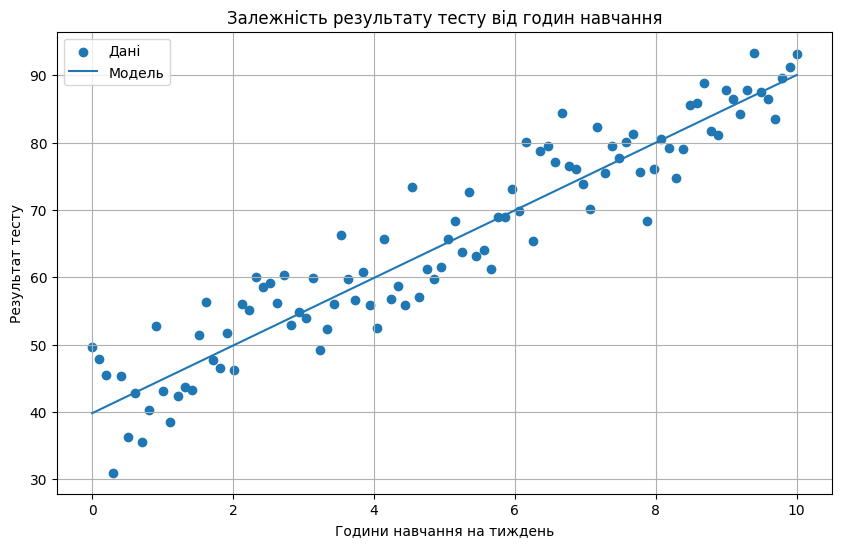

In [113]:
import matplotlib.pyplot as plt

# Дані Вправи 20
x_plot = x2.detach().numpy()
y_plot = y2.detach().numpy()

# Прогноз моделі
with torch.no_grad():
    y_pred = model2(x2.unsqueeze(1)).squeeze(1)

y_pred = y_pred.numpy()

# Сортуємо x, щоб лінія була правильно побудована
sort_idx = x_plot.argsort()
x_sorted = x_plot[sort_idx]
y_pred_sorted = y_pred[sort_idx]

# Графік
plt.figure(figsize=(10, 6))

plt.scatter(x_plot, y_plot, label="Дані")
plt.plot(x_sorted, y_pred_sorted, label="Модель")

plt.xlabel("Години навчання на тиждень")
plt.ylabel("Результат тесту")
plt.title("Залежність результату тесту від годин навчання")

plt.legend()
plt.grid(True)
plt.show()

**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [107]:
!pip install -q gradio
import gradio as gr

loaded_model = torch.nn.Linear(1, 1)
loaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
loaded_model.eval()

def predict_score(x_value):
    x_tensor = torch.tensor([[float(x_value)]], dtype=torch.float32)
    with torch.no_grad():
        prediction = loaded_model(x_tensor)
    return float(prediction.item())

demo = gr.Interface(
    fn=predict_score,
    inputs=gr.Number(label="x"),
    outputs=gr.Number(label="Прогноз y"),
    title="Лінійна регресія",
    description="Введіть значення x, щоб отримати прогноз y."
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://957826a29566033e5d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```